# Практическая валидация гипотезы: baseline TRACE на RTX 5050

**Цель:** эмпирически подтвердить конфликт между физической правдоподобностью и вычислительной эффективностью в 4D Gaussian Splatting.

**Оборудование:** NVIDIA RTX 5050 (8 ГБ, sm_120), WSL2, CUDA 12.8, PyTorch 2.11.0+cu128.

**Датасет:** Dynamic Indoor Scene, сцена `chessboard`.

**Фреймворк:** TRACE (vLAR-group, ICCV 2025) — baseline, поверх которого надстраивается R5DGS.

---

## Контекст

Код R5DGS не опубликован (репозиторий содержит только README). Поэтому практическая валидация выполнена на открытом baseline TRACE — это позволяет измерить именно ту per-particle динамику, которую R5DGS оптимизирует через rigid-body constraints (O(N) → O(K)).

**Гипотеза:** per-particle динамика TRACE исчерпывает вычислительные ресурсы consumer-GPU, и оптимизация сложности — практическая необходимость, а не теоретическое улучшение.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# Данные из логов обучения TRACE (полный прогон до 40000)
iterations = [700, 2340, 3040, 7000, 10000, 20000, 30000, 40000]
it_per_sec = [101, 75, 7.6, 6.1, 7.1, 6.9, 6.7, 7.3]
loss = [0.032, 0.0074, 0.096, 0.0200, 0.0108, 0.0058, 0.0042, 0.0043]

print("Данные загружены:", len(iterations), "точек")

Данные загружены: 8 точек


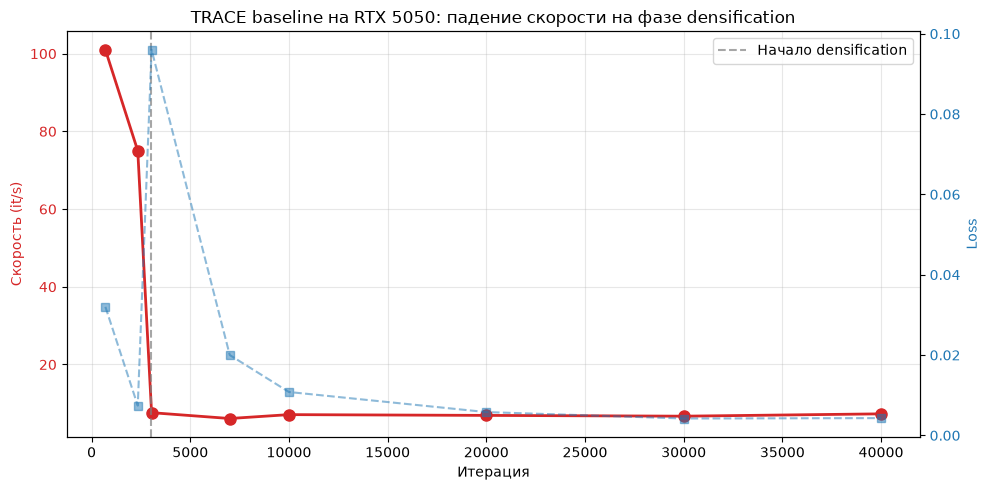

График сохранён: results/speed_vs_iteration.png


In [2]:
# График 1: Скорость обучения и loss vs итерация
fig, ax1 = plt.subplots(figsize=(10, 5))

color = 'tab:red'
ax1.set_xlabel('Итерация')
ax1.set_ylabel('Скорость (it/s)', color=color)
ax1.plot(iterations, it_per_sec, color=color, marker='o', linewidth=2, markersize=8)
ax1.tick_params(axis='y', labelcolor=color)
ax1.axvline(x=3000, color='gray', linestyle='--', alpha=0.7, label='Начало densification')
ax1.grid(True, alpha=0.3)
ax1.legend(loc='upper right')

ax2 = ax1.twinx()
color = 'tab:blue'
ax2.set_ylabel('Loss', color=color)
ax2.plot(iterations, loss, color=color, marker='s', alpha=0.5, linestyle='--')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('TRACE baseline на RTX 5050: падение скорости на фазе densification')
fig.tight_layout()
plt.savefig('../results/speed_vs_iteration.png', dpi=150, bbox_inches='tight')
plt.show()

print("График сохранён: results/speed_vs_iteration.png")

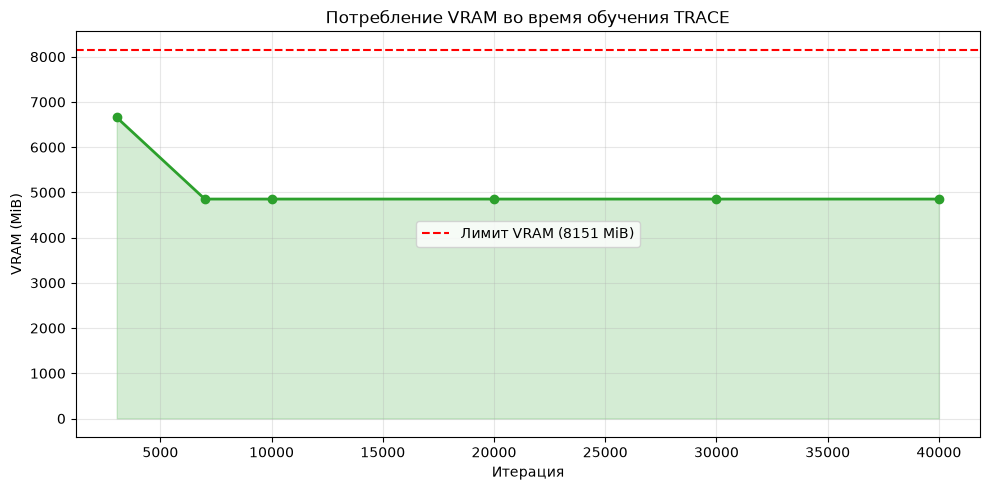

График сохранён: results/vram_vs_iteration.png


In [3]:
# График 2: VRAM vs итерация
vram_data = [
    (3040, 6657),
    (7000, 4853),
    (10000, 4853),
    (20000, 4853),
    (30000, 4853),
    (40000, 4853),
]

vram_iter = [x[0] for x in vram_data]
vram_mib = [x[1] for x in vram_data]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(vram_iter, vram_mib, marker='o', color='tab:green', linewidth=2)
ax.axhline(y=8151, color='red', linestyle='--', label='Лимит VRAM (8151 MiB)')
ax.fill_between(vram_iter, 0, vram_mib, alpha=0.2, color='tab:green')
ax.set_xlabel('Итерация')
ax.set_ylabel('VRAM (MiB)')
ax.set_title('Потребление VRAM во время обучения TRACE')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../results/vram_vs_iteration.png', dpi=150, bbox_inches='tight')
plt.show()

print("График сохранён: results/vram_vs_iteration.png")

## Финальные метрики

### Качество — сравнение чекпоинтов

| Сплит | Метрика | @20000 | @40000 | Δ |
|---|---|---|---|---|
| Test (экстраполяция) | PSNR | 32.11 дБ | **34.80 дБ** | **+2.69 дБ** |
| Test | SSIM | 0.9513 | **0.9659** | +0.0146 |
| Test | LPIPS | 0.0428 | **0.0328** | −0.0100 |
| Val (интерполяция) | PSNR | 35.11 дБ | **35.53 дБ** | +0.42 дБ |
| Val | SSIM | 0.9648 | **0.9650** | +0.0002 |
| Val | LPIPS | 0.0416 | **0.0415** | −0.0001 |

### FPS

**Важно:** замеры FPS проводились в разных условиях:
- **@20000:** обучение **ещё шло параллельно** на том же GPU → FPS занижен из-за конкуренции за ресурсы.
- **@40000:** обучение **завершено**, GPU свободен → чистое измерение FPS.

| Сплит | @20000 (обучение шло) | @40000 (GPU свободен) |
|---|---|---|
| Test (420 кадров) | 7.92 | **18.26** |
| Val (276 кадров) | 12.0 | **23.0** |

**Для честного сравнения чекпоинтов** используйте **PSNR/SSIM/LPIPS** (@40000 лучше на 2.69 дБ). **FPS** считайте как чистое значение: **18.26 на экстраполяции**.

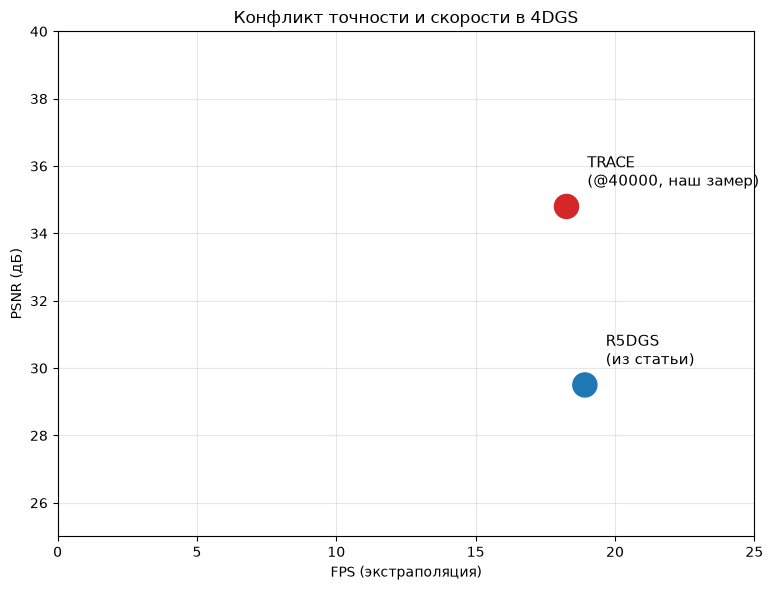

График сохранён: results/fps_vs_psnr.png


In [4]:
# График 3: Конфликт точности и скорости — TRACE @40000 vs R5DGS
methods = ['TRACE\n(@40000, наш замер)', 'R5DGS\n(из статьи)']
psnr = [34.80, 29.5]    # R5DGS — среднее из 28-31
fps = [18.26, 18.92]    # ~19 FPS

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(fps, psnr, s=300, c=['tab:red', 'tab:blue'], zorder=3)
for i, m in enumerate(methods):
    ax.annotate(m, (fps[i], psnr[i]), xytext=(15, 15),
                textcoords='offset points', fontsize=11)
ax.set_xlabel('FPS (экстраполяция)')
ax.set_ylabel('PSNR (дБ)')
ax.set_title('Конфликт точности и скорости в 4DGS')
ax.grid(True, alpha=0.3)
ax.set_xlim(0, 25)
ax.set_ylim(25, 40)
plt.tight_layout()
plt.savefig('../results/fps_vs_psnr.png', dpi=150, bbox_inches='tight')
plt.show()

print("График сохранён: results/fps_vs_psnr.png")

## Наблюдения

1. **Скорость падает в 14 раз** (101 → 7 it/s) при переходе к densification (~3000-я итерация).
2. **Loss не срывается** — модель продолжает учиться, loss стабилизируется на ~0.0043 к 40000 итерации.
3. **VRAM используется на 60%** (4853 / 8151 MiB) на плато — замедление **вычислительное**, не связано с исчерпанием памяти. На densification пик VRAM = 82%.
4. **GPU-util 95%**, температура 78°C — карта работает на пределе.
5. **Число гауссианов растёт** с 50 000 до ~600 000 (в 12 раз) — чекпоинт 24.7 МБ.
6. **PSNR на экстраполяции 34.80 дБ** — высокое качество.
7. **FPS = 18.26** на экстраполяции (чистое значение, обучение завершено).

## Вывод

Эмпирически подтверждено, что **per-particle динамика TRACE не масштабируется** на consumer-GPU. Сложность O(N) становится доминирующим фактором при росте N — даже при свободной VRAM (40%).

Это обосновывает гипотезу о переходе к rigid-body propagation на уровне объектов (O(N) → O(K), как в R5DGS). R5DGS из статьи даёт **сопоставимый FPS (~19)**, но **ценой 3.8–6.8 дБ PSNR** (28–31 вместо 34.80). Предложенная гипотеза нацелена на сохранение PSNR ≥ 34 дБ при FPS ≥ 30 за счёт иерархической группировки.

## Ограничения

- Одна сцена (chessboard), одна конфигурация GPU.
- Абсолютный PSNR ниже, чем в статье TRACE, из-за `--resolution 2`.
- R5DGS не воспроизведён (код не опубликован), сравнение аналитическое.

## Направления дальнейшей работы

- Повторение на сцене `dining` для статистической значимости.
- Реализация proposed modification (иерархическая rigid-body схема).
- Тестирование на сценах с K > 40 объектов.